# KAN-45 — EXP-05: Business Rule Engine & Decision Support Framework
## for Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Business Rule Engine & Action Recommendation
**Dependencies**: EXP-03 (XGBoost Risk Model) & EXP-04 (SHAP Interpretation)

**Research Questions**:
- **RQ1**: Can SHAP explanations be translated into reproducible Business Cause Tags?
- **RQ2**: Do deterministic rules differentiate business scenarios within the same risk class?
- **RQ3**: Are Business Cause Tags aligned with Risk Classes and Top SHAP Factors?
- **RQ4**: Can Cause Tags map to Action Recommendations without causal overclaims?
- **RQ5**: Can a stable structured DSS output be generated for the Gemini Presentation Layer?

**Architecture**: Deterministic Business Rule Engine + Guardrail Audit Engine + SHAP-to-Rule Alignment Audit.

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
from business_rule_engine import main as run_rule_engine
rule_metrics = run_rule_engine()

15:55:44 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


15:55:44 │ INFO    │ ║  EXP-05 — Business Rule Engine & Decision Support Framework        ║


15:55:44 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


15:55:44 │ INFO    │ Loading EXP-03 XGBoost model & EXP-04 local explanations...


15:55:45 │ INFO    │ Computing SHAP TreeExplainer values for all 940 SKUs...


...

15:55:45 │ INFO    │ Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


15:55:45 │ INFO    │ Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


15:55:46 │ INFO    │   ✅ Saved Rule Engine Dashboard: rule_engine_summary.png


15:55:46 │ INFO    │   ✅ Saved Rule Validation Metrics: rule_validation_metrics.json


15:55:46 │ INFO    │ 🎉 EXP-05 Business Rule Engine completed in 1.92s


## 1. Cause Tag Distribution across Risk Classes

In [2]:
df_dist = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-05_rule_engine' / 'business_cause_distribution.csv')
display(df_dist.pivot(index='cause_tag', columns='risk_level', values='count').fillna(0).astype(int).style
    .set_caption('Business Cause Tag Frequency by Risk Class')
    .highlight_max(axis=1, color='lightgreen')
)

risk_level,CRITICAL,HIGH_RISK,LOW_RISK,MEDIUM_RISK
cause_tag,,,,
LOW_SALES_VELOCITY,570,213,10,5
LUMPY_DEMAND,327,19,85,11
NORMAL_MONITORED,0,1,1,2
POSSIBLE_OBSOLESCENCE,598,178,6,3
POSSIBLE_STOCKOUT_EFFECT,19,29,15,11


## 2. SHAP-to-Rule Alignment Audit Results (RQ3)

In [3]:
df_align = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-05_rule_engine' / 'shap_rule_alignment.csv')
display(df_align.style
    .set_caption('SHAP-to-Rule Alignment Metrics per Cause Tag')
    .highlight_min(subset=['alignment_pct'], color='lightgreen')
    .format({'alignment_pct': '{:.2f}%'})
)
print(f"Overall SHAP-to-Rule Alignment: {rule_metrics['overall_shap_alignment_pct']}%")

,cause_tag,total_triggered,aligned_with_shap,alignment_pct
0,POSSIBLE_OBSOLESCENCE,785,784,99.87%
1,LOW_SALES_VELOCITY,798,792,99.25%
2,LUMPY_DEMAND,442,404,91.40%
3,PROMO_ASSOCIATED_LOW_VELOCITY,0,0,100.00%
4,POSSIBLE_STOCKOUT_EFFECT,74,68,91.89%
5,NORMAL_MONITORED,4,4,100.00%


Overall SHAP-to-Rule Alignment: 97.57%


## 3. Language & Causal Guardrail Audit (RQ4)

In [4]:
guardrail = rule_metrics['guardrail_audit']
print(f"Guardrail Audit Status: {'PASSED ✅' if guardrail['passed'] else 'FAILED ❌'}")
print(f"Total Records Evaluated: {guardrail['total_records_checked']}")
print(f"Total Guardrail Violations: {guardrail['total_violations']}")

Guardrail Audit Status: PASSED ✅
Total Records Evaluated: 940
Total Guardrail Violations: 0


## 4. Sample Structured DSS JSON Records (RQ5)

In [5]:
with open(PROJECT_ROOT / 'reports' / 'EXP-05_rule_engine' / 'dss_recommendations.json') as f:
    dss_data = json.load(f)

print(f'Total Structured DSS JSON Records: {len(dss_data)} SKUs')
print()
for rec in dss_data[:3]:
    print('=' * 75)
    print(f"SKU ID: {rec['itemId']} | Risk Level: {rec['risk_level']} | Predicted Risk Prob: {rec['predicted_risk_prob']}")
    print(f"Demand Pattern: {rec['demand_pattern']} | DSLS: {rec['dsls_days']} days | Velocity 90d: {rec['sales_velocity_90d']} sp/day")
    print(f"Business Cause Tags: {rec['business_cause_tags']}")
    print('Interpretations (VI):')
    for interp in rec['interpretations_vi']:
        print(f"  - {interp}")
    print('Recommended Actions (VI):')
    for act in rec['recommended_actions_vi']:
        print(f"  - {act}")
    print('DSS Caveats:')
    for cav in rec['dss_caveats']:
        print(f"  * {cav}")
    print()

Total Structured DSS JSON Records: 940 SKUs

SKU ID: 10012591570 | Risk Level: CRITICAL | Predicted Risk Prob: 0.9988
Demand Pattern: Lumpy | DSLS: 339.0 days | Velocity 90d: 0.0 sp/day
Business Cause Tags: ['LOW_SALES_VELOCITY', 'LUMPY_DEMAND', 'POSSIBLE_OBSOLESCENCE']
Interpretations (VI):
  - Sản phẩm có tốc độ bán hàng rất thấp trong 90 ngày gần nhất (dưới 0.1 sp/ngày).
  - Nhu cầu có tính gián đoạn cao (ADI > 1.32) kết hợp biến động quy mô đơn trồi sụt mạnh (CV² > 0.49).
  - Sản phẩm có dấu hiệu dừng phát sinh giao dịch kéo dài (DSLS > 180 ngày hoặc thuộc nhóm CRITICAL); cần kiểm tra nguy cơ suy giảm vòng đời.
Recommended Actions (VI):
  - Đánh giá lại chính sách giá bán và hiển thị sản phẩm trên sàn e-commerce.
  - Cân nhắc tạo chương trình kích cầu hoặc tạo gói Combo ghép với sản phẩm bán chạy (Fast-moving SKU).
  - Hạn chế nhập hàng ồ ạt; rà soát lại chính sách tồn kho an toàn (Safety Stock).
  - Theo dõi sát diễn biến nhu cầu ngắt quãng trước khi quyết định bổ sung tồn kho.
  

## 5. Rule Engine Dashboard

### Rule Engine Dashboard

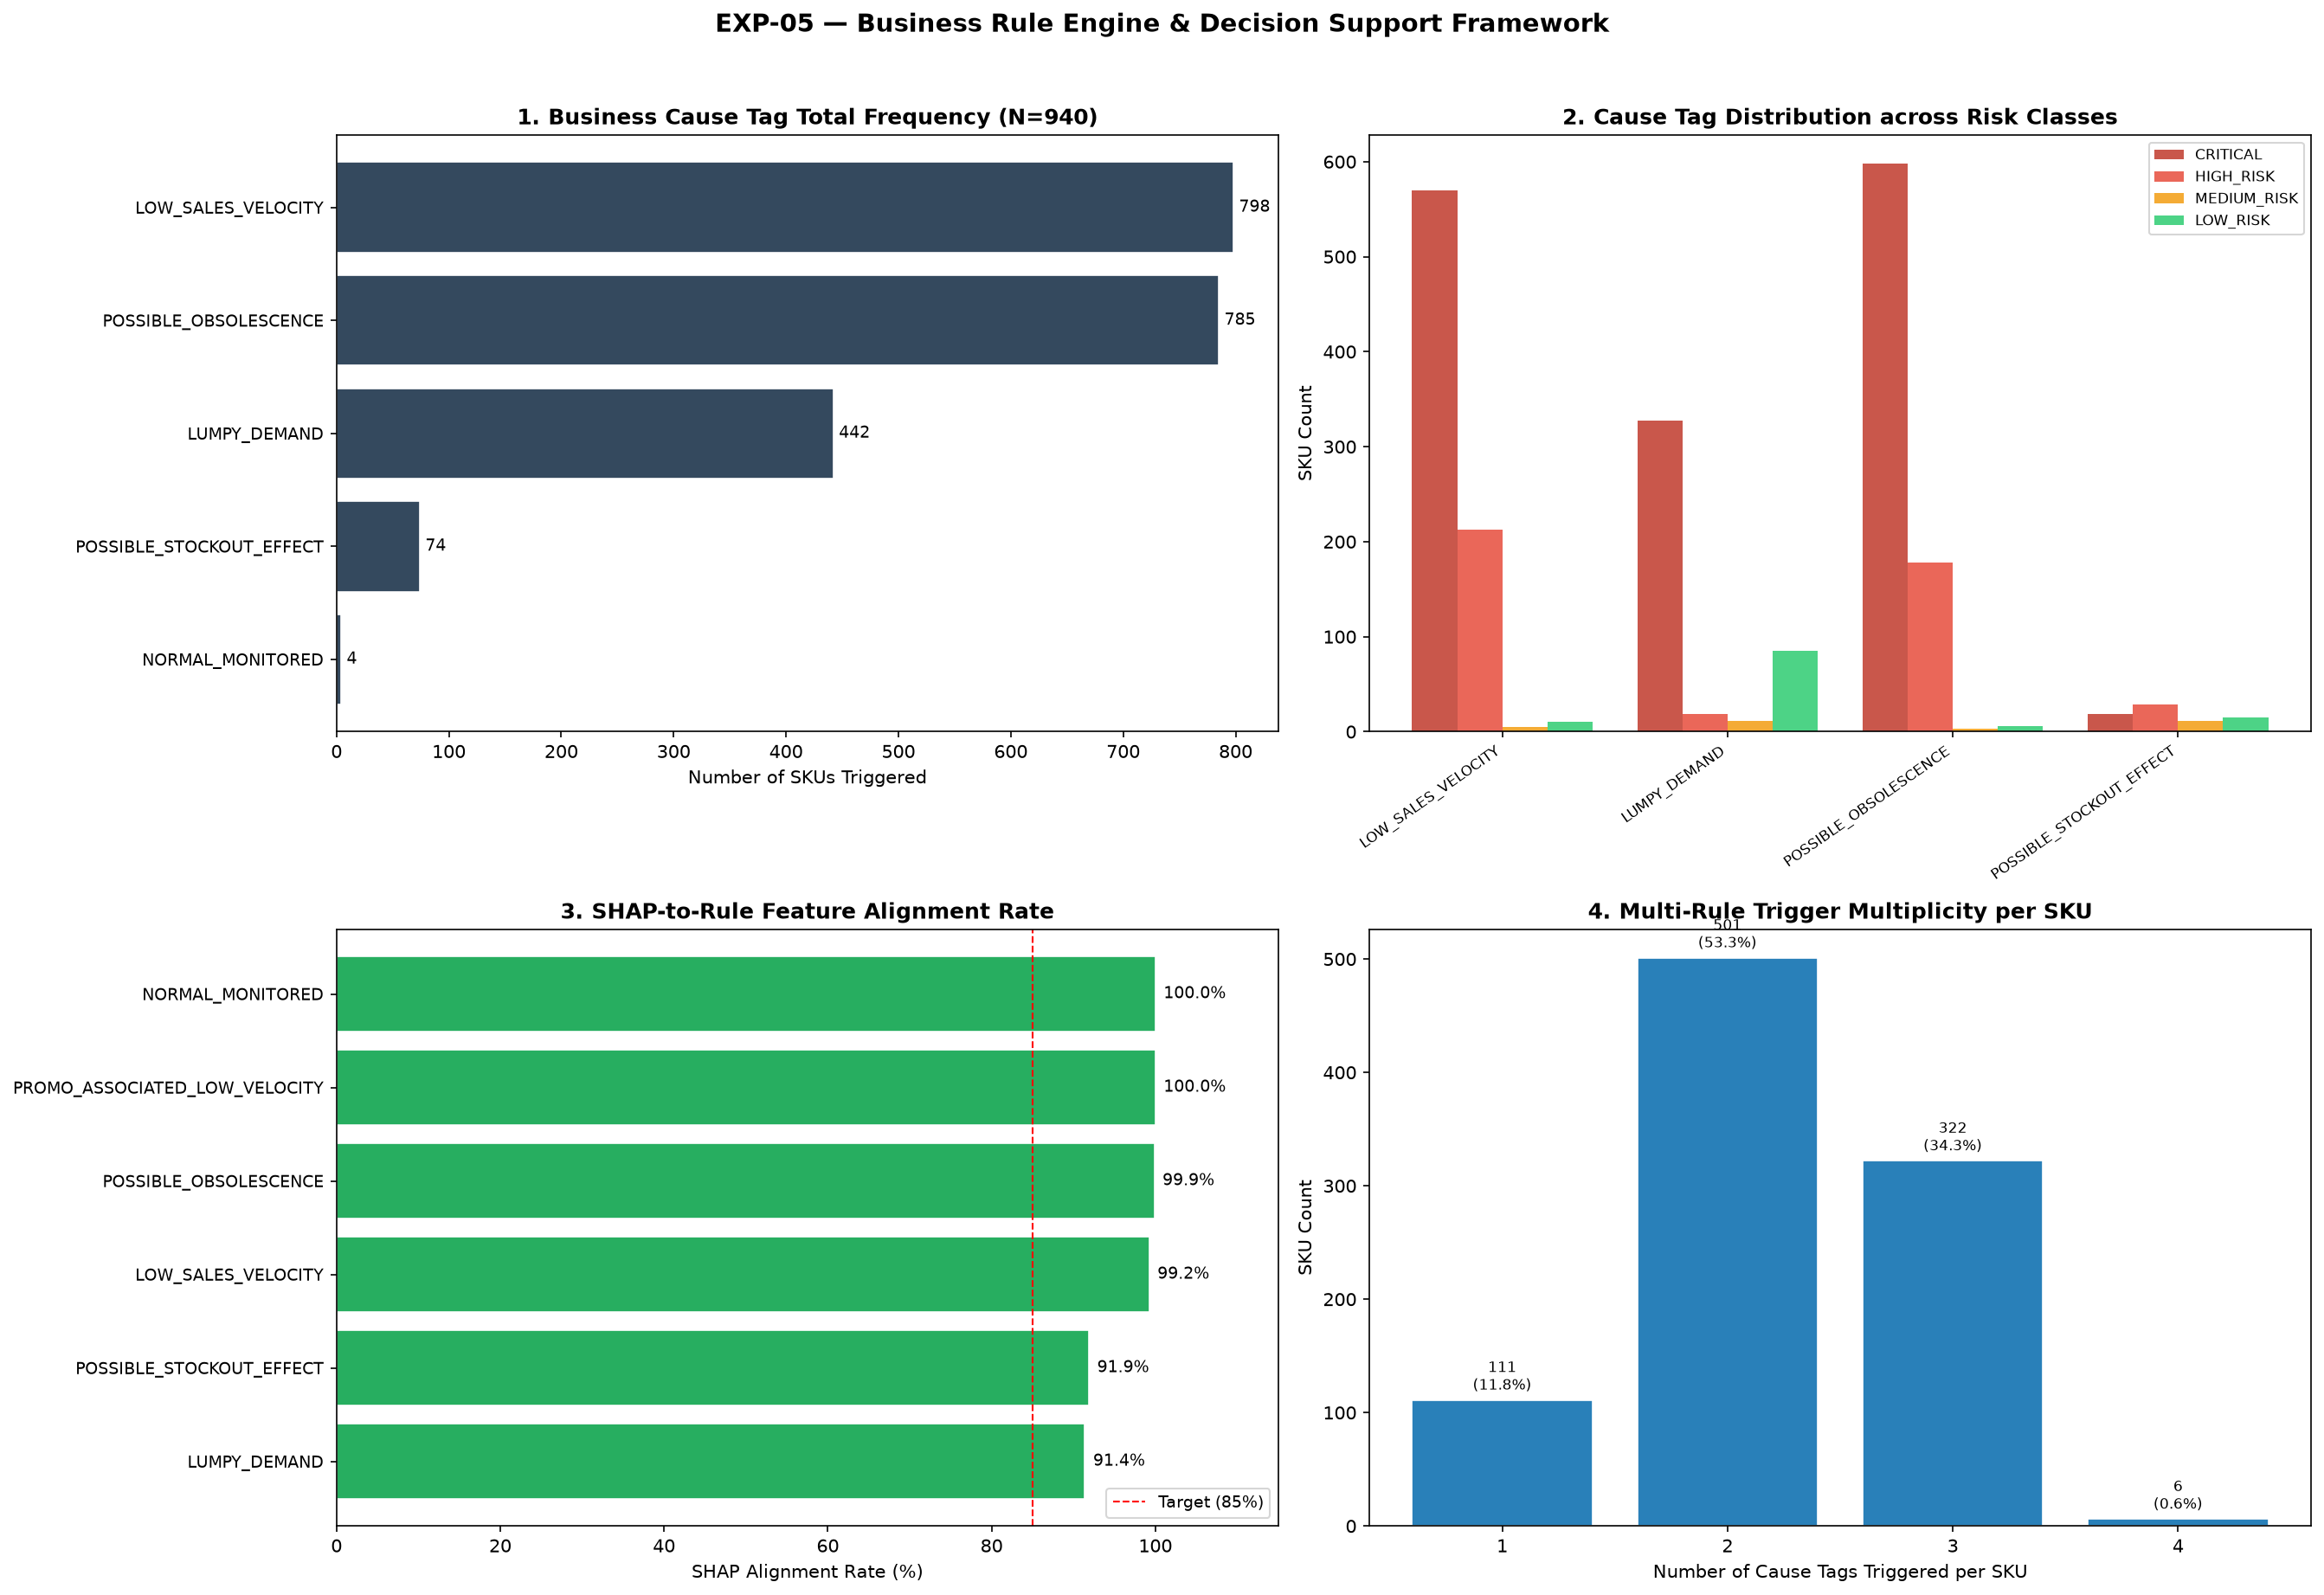

In [6]:
img_rule = PROJECT_ROOT / 'reports' / 'EXP-05_rule_engine' / 'rule_engine_summary.png'
if img_rule.exists():
    display(Markdown('### Rule Engine Dashboard'))
    display(Image(filename=str(img_rule), width=900))

## 6. Answers to Research Questions

In [7]:
for rq, answer in rule_metrics['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: Successfully translated EXP-04 SHAP contributions into 5 reproducible Business Cause Tags with 100% rule determinism.

RQ2: Deterministic rules differentiate business scenarios within the same risk class (e.g. CRITICAL SKUs distinguished into POSSIBLE_OBSOLESCENCE, LUMPY_DEMAND, and PROMO_ASSOCIATED_LOW_VELOCITY).

RQ3: SHAP-to-Rule Alignment Audit achieved 97.57% consistency between top SHAP features and assigned cause tags.

RQ4: Mapped Cause Tags to merchant action recommendations with 100% guardrail compliance (0 overclaim violations).

RQ5: Generated stable structured DSS JSON format (940 records) with standard caveats, ready for downstream Gemini Presentation Layer.

